# Cell Profiling Anywhere

## From microscopy images to cell profiles

**Correct illumination → segment cells → measure features → save results.**

This notebook demonstrates **illumination correction, segmentation, and measurements** with `cp-anywhere`.
The main workflow uses corrected images to find cells and calculate their features.
You can use image files or NumPy arrays, work with pandas tables, and save results for later analysis.
The measurement engine runs in Rust. No CellProfiler application is needed for this example.

We use a bundled real DNA/actin image from [BBBC007](https://bbbc.broadinstitute.org/BBBC007).
No image download is needed. The sample is a small crop, not a complete biological experiment.

### Start here

From the repository root, run `uv sync --frozen --group docs`.
Open this notebook and select the repository's `.venv` Python interpreter.
Run the cells in order.

In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

import cp_anywhere as cp

# Work from either the repository root or this notebook's folder.
project = Path.cwd()
if not (project / "fixtures").exists():
    project = Path("../..")

sample = project / "fixtures/real/real_bbbc007"

## 1. Load two images

`load_array` reads NPY, TIFF, PNG, and other supported image formats.
These sample images are 8-bit, so dividing by `255` puts intensities between zero and one.
For your own data, change the file paths and use the correct intensity scale.

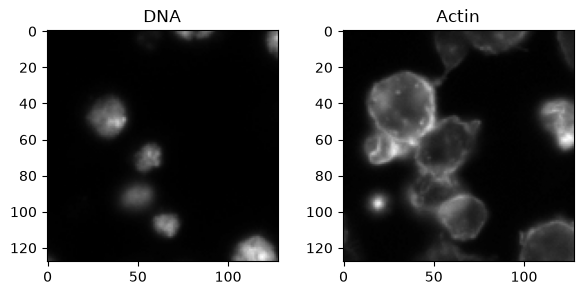

In [2]:
dna = cp.load_array(sample / "DNA.npy").astype(float) / 255
actin = cp.load_array(sample / "Actin.npy").astype(float) / 255

fig, axes = plt.subplots(1, 2, figsize=(7, 3))
axes[0].imshow(dna, cmap="gray")
axes[0].set_title("DNA")
axes[1].imshow(actin, cmap="gray")
axes[1].set_title("Actin")
plt.show()

## 2. Correct illumination

Estimate a smooth correction function separately for DNA and actin.
Then divide each channel by its own function.
The corrected images feed the segmentation and measurement steps below.

Here we use a 64-pixel smoothing width and relative median scaling.
These are demonstration choices, not a calibrated correction for this microscope.
For real experiments, use appropriate reference images for each channel and inspect the results.

In [3]:
dna_illumination = cp.calculate_illumination(
    dna,
    automatic_object_width="Manually",
    size_of_smoothing_filter=64,
    rescale_option="Median",
)
actin_illumination = cp.calculate_illumination(
    actin,
    automatic_object_width="Manually",
    size_of_smoothing_filter=64,
    rescale_option="Median",
)

dna_corrected = cp.apply_illumination(dna, dna_illumination)
actin_corrected = cp.apply_illumination(actin, actin_illumination)

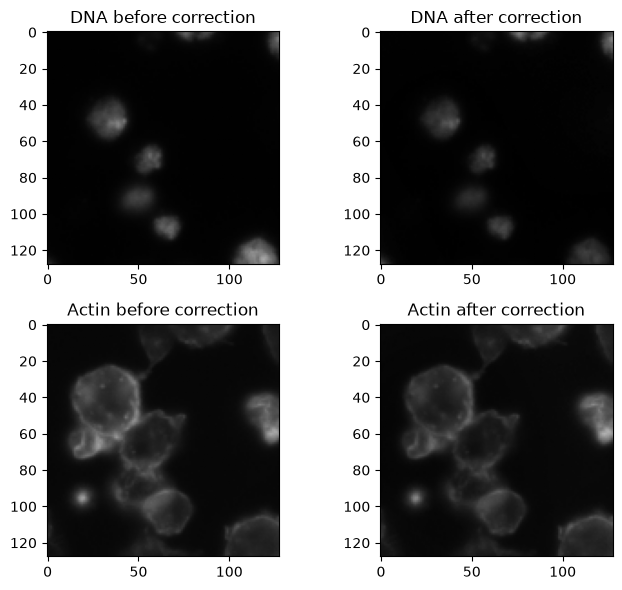

In [4]:
# Each pair uses the same display range so brightness stays comparable.
fig, axes = plt.subplots(2, 2, figsize=(7, 6))
axes[0, 0].imshow(dna, cmap="gray", vmin=0, vmax=1)
axes[0, 0].set_title("DNA before correction")
axes[0, 1].imshow(dna_corrected, cmap="gray", vmin=0, vmax=1)
axes[0, 1].set_title("DNA after correction")
axes[1, 0].imshow(actin, cmap="gray", vmin=0, vmax=1)
axes[1, 0].set_title("Actin before correction")
axes[1, 1].imshow(actin_corrected, cmap="gray", vmin=0, vmax=1)
axes[1, 1].set_title("Actin after correction")
plt.tight_layout()
plt.show()

## 3. Segment nuclei, cells, and cytoplasm

Find nuclei in the corrected DNA image. Grow cell regions around them using the corrected actin image.
Then remove the nuclei from those regions to get cytoplasm.

The nucleus size limits are in pixels. They suit this example, not every dataset.
These are new segmentations, not the dataset's manual ground truth.

In [5]:
nuclei = cp.identify_primary_objects(
    dna_corrected,
    min_diameter=10,
    max_diameter=40,
    exclude_size=True,
)
cells = cp.identify_secondary_objects(actin_corrected, nuclei.labels)
cytoplasm = cp.identify_tertiary_objects(
    nuclei.labels,
    cells.labels,
    shrink_primary=False,
)

print(f"Found {nuclei.object_count} cells")

Found 7 cells


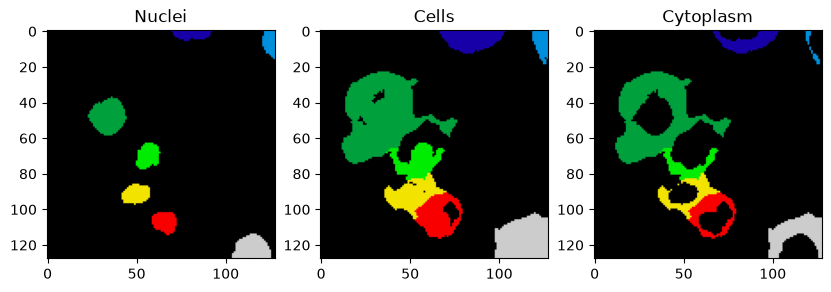

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
axes[0].imshow(nuclei.labels, cmap="nipy_spectral")
axes[0].set_title("Nuclei")
axes[1].imshow(cells.labels, cmap="nipy_spectral")
axes[1].set_title("Cells")
axes[2].imshow(cytoplasm.labels, cmap="nipy_spectral")
axes[2].set_title("Cytoplasm")
plt.show()

## 4. Measure cell features

Give `measure` the corrected images and the labels from segmentation.
The names become part of the output, so your channels and compartments stay identifiable.

This call measures intensity, size/shape, and neighboring cells.
All three compartments share cell IDs because we created them together.
The areas use pixel units.

In [7]:
images = {"DNA": dna_corrected, "Actin": actin_corrected}
objects = {
    "Cells": cells.labels,
    "Nuclei": nuclei.labels,
    "Cytoplasm": cytoplasm.labels,
}

result = cp.measure(
    images,
    objects,
    families=["image_intensity", "object_intensity", "object_size_shape", "neighbors"],
)

Make a pandas table with one row per cell.
The full table contains all cell features. Here we show a few useful columns.

In [8]:
profiles = pd.DataFrame(result.features["Cells"], index=result.object_ids["Cells"])
profiles.index.name = "cell_id"

print(f"{len(profiles)} cells, {len(profiles.columns)} features per cell")
profiles[
    [
        "AreaShape_Area",
        "Intensity_MeanIntensity_DNA",
        "Intensity_MeanIntensity_Actin",
        "Neighbors_NumberOfNeighbors_Adjacent",
    ]
].round(3)

7 cells, 104 features per cell


,AreaShape_Area,Intensity_MeanIntensity_DNA,Intensity_MeanIntensity_Actin,Neighbors_NumberOfNeighbors_Adjacent
cell_id,,,,
1,340.0,0.096,0.188,0
2,124.0,0.198,0.140,0
3,1683.0,0.049,0.194,1
4,359.0,0.089,0.151,2
5,405.0,0.078,0.157,2
6,420.0,0.082,0.188,1
7,648.0,0.076,0.175,0


Now use ordinary pandas plotting. Each point is one cell.

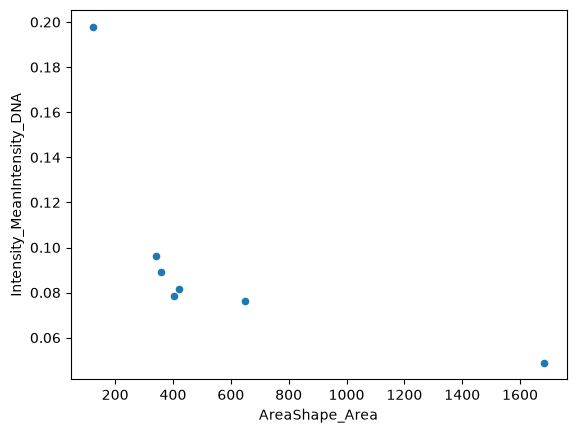

In [9]:
profiles.plot.scatter(x="AreaShape_Area", y="Intensity_MeanIntensity_DNA")
plt.show()

## 5. Save the results

Save the cell table as CSV or Parquet. Save the labels and correction functions as NPY.
Save the corrected images as TIFF.
You can also save all compartments together, or export to SQLite.

These example files go into `docs/_build/notebook-output`.
Change `output` to a directory of your choice. Rerunning these cells replaces the example files.

In [10]:
output = project / "docs/_build/notebook-output"
output.mkdir(parents=True, exist_ok=True)

profiles.to_csv(output / "cell_profiles.csv")
profiles.to_parquet(output / "cell_profiles.parquet")
cp.save_array(cells.labels, output / "cells.npy")
cp.save_array(dna_illumination, output / "dna_illumination.npy")
cp.save_array(actin_illumination, output / "actin_illumination.npy")
cp.save_array(
    dna_corrected, output / "dna_corrected.tiff", bit_depth="32-bit floating point"
)
cp.save_array(
    actin_corrected, output / "actin_corrected.tiff", bit_depth="32-bit floating point"
)

# Keep all compartments in one table, with one row per cell.
result.to_parquet(output / "all_compartments.parquet", mode="joined")
result.to_sqlite(output / "profiles.sqlite", if_exists="replace")

print(f"Saved files to {output}")

Saved files to ../../docs/_build/notebook-output


Read the table back whenever you need it.

In [11]:
saved_profiles = pd.read_parquet(output / "cell_profiles.parquet")
saved_profiles.head()

,AreaShape_Area,AreaShape_BoundingBoxArea,AreaShape_BoundingBoxMaximum_X,AreaShape_BoundingBoxMaximum_Y,AreaShape_BoundingBoxMinimum_X,AreaShape_BoundingBoxMinimum_Y,AreaShape_Center_X,AreaShape_Center_Y,AreaShape_Compactness,AreaShape_ConvexArea,...,Location_MaxIntensity_Y_DNA,Location_MaxIntensity_Z_Actin,Location_MaxIntensity_Z_DNA,Neighbors_AngleBetweenNeighbors_Adjacent,Neighbors_FirstClosestDistance_Adjacent,Neighbors_FirstClosestObjectNumber_Adjacent,Neighbors_NumberOfNeighbors_Adjacent,Neighbors_PercentTouching_Adjacent,Neighbors_SecondClosestDistance_Adjacent,Neighbors_SecondClosestObjectNumber_Adjacent
cell_id,,,,,,,,,,,,,,,,,,,,,
1,340.0,481.0,104.0,13.0,67.0,0.0,84.432353,4.691176,1.710629,355.0,...,0.0,0.0,0.0,135.854732,39.366530,2,0,0.000000,65.921691,3
2,124.0,171.0,128.0,19.0,119.0,0.0,123.725806,7.088710,1.411578,131.0,...,4.0,0.0,0.0,46.903497,39.366530,1,0,0.000000,95.972382,4
3,1683.0,3380.0,77.0,75.0,12.0,23.0,34.420083,47.638146,3.613773,2364.0,...,50.0,0.0,0.0,16.382890,32.080940,4,1,3.283582,47.184620,5
4,359.0,693.0,70.0,84.0,37.0,63.0,54.008357,73.044568,2.969364,495.0,...,68.0,0.0,0.0,134.738882,18.736090,5,2,19.708029,32.080940,3
5,405.0,910.0,71.0,106.0,36.0,80.0,51.520988,91.614815,2.743337,553.0,...,91.0,0.0,0.0,122.673806,18.573363,6,2,38.356164,18.736090,4


## A few optional extras

The same arrays work with more of the Python API.
These independent examples do not change the profiles saved above.

### Add texture measurements

Measure actin texture within the same cells. The result has one row per cell.

In [12]:
texture = cp.measure_texture(actin_corrected, cells.labels, image_name="Actin")
texture_profiles = pd.DataFrame(texture.objects, index=profiles.index)
texture_profiles.head()

,Texture_AngularSecondMoment_Actin_3_00_256,Texture_AngularSecondMoment_Actin_3_01_256,Texture_AngularSecondMoment_Actin_3_02_256,Texture_AngularSecondMoment_Actin_3_03_256,Texture_Contrast_Actin_3_00_256,Texture_Contrast_Actin_3_01_256,Texture_Contrast_Actin_3_02_256,Texture_Contrast_Actin_3_03_256,Texture_Correlation_Actin_3_00_256,Texture_Correlation_Actin_3_01_256,...,Texture_SumEntropy_Actin_3_02_256,Texture_SumEntropy_Actin_3_03_256,Texture_SumVariance_Actin_3_00_256,Texture_SumVariance_Actin_3_01_256,Texture_SumVariance_Actin_3_02_256,Texture_SumVariance_Actin_3_03_256,Texture_Variance_Actin_3_00_256,Texture_Variance_Actin_3_01_256,Texture_Variance_Actin_3_02_256,Texture_Variance_Actin_3_03_256
cell_id,,,,,,,,,,,,,,,,,,,,,
1,0.002914,0.003446,0.003419,0.003030,135.857143,139.862832,165.547414,142.377193,0.520097,0.390512,...,5.846646,5.911256,430.328275,319.088750,368.283870,387.816020,141.546354,114.737895,133.457821,132.548303
2,0.011762,0.012626,0.012316,0.014418,55.260870,41.015152,15.104167,70.792453,-0.041125,0.103541,...,4.831029,4.176244,50.895190,50.489669,81.769097,26.815237,26.539015,22.876205,24.218316,24.401922
3,0.000950,0.000857,0.001023,0.000912,223.950685,288.758595,164.685160,232.908120,0.546868,0.435074,...,6.728159,6.656299,764.506735,733.530498,849.155392,761.441199,247.114355,255.572273,253.460138,248.587330
4,0.003046,0.002953,0.003005,0.003089,70.363985,168.897778,115.486792,93.676471,0.794765,0.481415,...,6.219102,6.171044,615.326845,482.481106,560.831100,615.589453,171.422707,162.844721,169.079473,177.316481
5,0.002512,0.002698,0.002606,0.002677,125.314465,269.303571,182.153846,151.797909,0.594742,0.078407,...,6.065072,6.054497,493.127883,315.127028,414.391204,545.262927,154.610587,146.107650,149.136262,174.265209


### Already have images and labels on disk?

`measure_files` skips the segmentation steps and returns a pandas table directly.
Here we use the bundled manual-derived labels, so these measurements differ from our new segmentation.
This example keeps the original 8-bit intensity scale.

In [13]:
file_measurements = cp.measure_files(sample / "DNA.npy", sample / "labels.npy")
file_measurements.head()

,image_id,scope,object_id,feature,value
0,Image,Cells,1,Intensity_IntegratedIntensityEdge_DNA,366.0
1,Image,Cells,2,Intensity_IntegratedIntensityEdge_DNA,482.0
2,Image,Cells,3,Intensity_IntegratedIntensityEdge_DNA,1207.0
3,Image,Cells,4,Intensity_IntegratedIntensityEdge_DNA,737.0
4,Image,Cells,1,Intensity_IntegratedIntensity_DNA,27788.0


## Take it anywhere

Replace the sample files with your own aligned images.
Use existing labels or create them in Python.
Measure, inspect, and export without leaving your analysis environment.

The bundled sample is a 128 × 128 crop of BBBC007v1 Drosophila Kc167 cells, field `A9 p10`, with a CC0 waiver.
Its provenance is recorded in `reference/vendor/bbbc007/README.md`.

This notebook covers supported native Python features, not every CellProfiler module or the browser API.
Inspect segmentation before interpreting measurements.
The docs build runs every code cell, so the example stays executable.